# Tiny ImageNet Classification with a Simplex LDA Head
This notebook follows `CIFAR100.ipynb`: train a convolutional encoder with a fixed
identity-covariance LDA head using `nn.NLLLoss()`, fit a post-hoc temperature on
held-out training examples, and compare validation confidence and reliability
before and after calibration.

Run from the `simplex-lda` directory with PyTorch, torchvision, Pillow, NumPy,
and Matplotlib installed. The data loaders come from `train_tiny_imagenet.py`
and preserve the class order in `wnids.txt` for both splits. Images stay at 64×64.
The labeled official validation set is used for reporting; the official test
images have no public labels. No validation examples are used to fit the temperature.


### Setup


In [1]:
from pathlib import Path

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import transforms
from lda import SimplexLDAHead
from train_tiny_imagenet import TinyImageNetTrain, TinyImageNetVal, resolve_data_root


In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device =', device)


device = cuda


### Data


In [3]:
# Accept either the extracted dataset directory or its parent.
# Set download=True to download/extract Tiny ImageNet if it is missing.
data_root = resolve_data_root(Path('data') / 'tiny-imagenet-200', download=False)
batch_size = 256
eval_batch_size = 1024
num_workers = 4  # Set to 0 if multiprocessing is unavailable.
epochs = 100
calibration_fraction = 0.1
split_seed = 42

mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)
pin_memory = torch.cuda.is_available()

train_tfm = transforms.Compose([
    transforms.RandomCrop(64, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
val_tfm = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_ds = TinyImageNetTrain(data_root, transform=train_tfm)
val_ds = TinyImageNetVal(data_root, transform=val_tfm)
if not train_ds or not val_ds:
    raise ValueError(f'No training or validation images found under {data_root}.')
num_classes = len(train_ds.wnids)
assert num_classes == 200, f'Expected 200 classes, found {num_classes}.'
assert train_ds.wnid_to_idx == val_ds.wnid_to_idx

# Exclude calibration examples from training before any model fitting.
calibration_size = int(len(train_ds) * calibration_fraction)
assert 0 < calibration_size < len(train_ds)
train_subset, calibration_subset = random_split(
    train_ds, [len(train_ds) - calibration_size, calibration_size],
    generator=torch.Generator().manual_seed(split_seed),
)
# Same training images and ordering, with deterministic evaluation transforms.
calibration_source_ds = TinyImageNetTrain(data_root, transform=val_tfm)
calibration_ds = Subset(calibration_source_ds, calibration_subset.indices)
train_ld = DataLoader(train_subset, batch_size=batch_size, shuffle=True,
                      num_workers=num_workers, pin_memory=pin_memory)
calibration_ld = DataLoader(calibration_ds, batch_size=eval_batch_size, shuffle=False,
                            num_workers=num_workers, pin_memory=pin_memory)
val_ld = DataLoader(val_ds, batch_size=eval_batch_size, shuffle=False,
                    num_workers=num_workers, pin_memory=pin_memory)
print(f'Train: {len(train_subset):,} | Calibration: {len(calibration_ds):,} | '
      f'Validation: {len(val_ds):,} | Classes: {num_classes}')


Train: 90,000 | Calibration: 10,000 | Validation: 10,000 | Classes: 200


### Model: encoder + LDA head with fixed identity covariance


In [4]:
class Encoder(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1),
        )
        self.proj = nn.Linear(256, dim)

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        return self.proj(x)

class DeepLDA(nn.Module):
    def __init__(self, C, D):
        super().__init__()
        self.encoder = Encoder(D)
        self.head = SimplexLDAHead(C, D, covariance_type="identity")

    def forward(self, x):
        z = self.encoder(x)
        return self.head(z)


### Train & Eval


In [5]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    ok = tot = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        ok += (logits.argmax(1) == y).sum().item()
        tot += y.size(0)
    return ok / tot

model = DeepLDA(C=num_classes, D=num_classes - 1).to(device)
opt = torch.optim.Adam(model.parameters())
loss_fn = nn.NLLLoss()

train_acc = []
val_acc = []

for epoch in range(1, epochs + 1):
    model.train()
    loss_sum = acc_sum = n_sum = 0
    for x, y in train_ld:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = loss_fn(logits, y)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        with torch.no_grad():
            pred = logits.argmax(1)
            acc_sum += (pred == y).sum().item()
            n_sum += y.size(0)
            loss_sum += loss.item() * y.size(0)
    tr_acc = acc_sum / n_sum
    va_acc = evaluate(model, val_ld)
    train_acc.append(tr_acc)
    val_acc.append(va_acc)
    print(f"[{epoch:02d}] train loss={loss_sum/n_sum:.4f} acc={tr_acc:.4f} | val acc={va_acc:.4f}")


[01] train loss=14.2660 acc=0.0454 | val acc=0.0685
[02] train loss=14.0733 acc=0.0991 | val acc=0.1022
[03] train loss=13.9608 acc=0.1397 | val acc=0.1374
[04] train loss=13.8412 acc=0.1697 | val acc=0.1398
[05] train loss=13.7141 acc=0.1943 | val acc=0.1811
[06] train loss=13.5817 acc=0.2188 | val acc=0.1993
[07] train loss=13.4548 acc=0.2418 | val acc=0.2364
[08] train loss=13.3264 acc=0.2627 | val acc=0.2386
[09] train loss=13.2100 acc=0.2809 | val acc=0.2632
[10] train loss=13.0991 acc=0.2981 | val acc=0.2822
[11] train loss=12.9949 acc=0.3131 | val acc=0.2662
[12] train loss=12.8992 acc=0.3280 | val acc=0.2922
[13] train loss=12.8034 acc=0.3407 | val acc=0.3133
[14] train loss=12.7171 acc=0.3504 | val acc=0.3255
[15] train loss=12.6351 acc=0.3625 | val acc=0.3325
[16] train loss=12.5558 acc=0.3703 | val acc=0.3413
[17] train loss=12.4782 acc=0.3797 | val acc=0.3267
[18] train loss=12.4139 acc=0.3888 | val acc=0.3556
[19] train loss=12.3405 acc=0.3971 | val acc=0.3553
[20] train l

### Post-hoc temperature scaling

Rerun the data and training cells above so calibration examples are excluded from
model training. With the trained model in evaluation mode, fit a single positive
scalar `T` on the held-out calibration set by minimizing cross-entropy (predictive
NLL, rather than the unnormalized log-score training objective). Calibrated probabilities are
`softmax(logits / T)`; the predicted class is unchanged. Validation labels are used only
for reporting, never for fitting the temperature. The plots below show both the original predictions and the calibrated
predictions on the validation set.


In [6]:
@torch.no_grad()
def collect_logits(model, loader):
    model.eval()
    logits, labels = [], []
    for x, y in loader:
        logits.append(model(x.to(device)).detach().cpu())
        labels.append(y.cpu())
    return torch.cat(logits), torch.cat(labels)


def fit_temperature(logits, labels):
    # Cache detached scores: only this scalar receives calibration gradients.
    logits = logits.detach().double()
    labels = labels.to(logits.device)
    log_temperature = nn.Parameter(logits.new_zeros(()))
    optimizer = torch.optim.LBFGS(
        [log_temperature], lr=0.1, max_iter=100, line_search_fn='strong_wolfe'
    )

    def closure():
        optimizer.zero_grad()
        loss = F.cross_entropy(logits / log_temperature.exp(), labels)
        loss.backward()
        return loss

    baseline_nll = F.cross_entropy(logits, labels).item()
    optimizer.step(closure)
    with torch.no_grad():
        temperature = log_temperature.exp()
        fitted_nll = F.cross_entropy(logits / temperature, labels)
        if (not torch.isfinite(temperature).item() or temperature.item() <= 0
                or not torch.isfinite(fitted_nll).item()
                or fitted_nll.item() > baseline_nll):
            raise RuntimeError('Temperature fitting failed to improve calibration NLL.')
    return temperature.item()


calibration_logits, calibration_labels = collect_logits(model, calibration_ld)
temperature = fit_temperature(calibration_logits, calibration_labels)
print(f'Fitted temperature: {temperature:.4f}')


@torch.no_grad()
def calibrated_probabilities(x):
    """Return calibrated class probabilities for a batch of images."""
    model.eval()
    return F.softmax(model(x.to(device)) / temperature, dim=1)


Fitted temperature: 1.2368


In [7]:
@torch.no_grad()
def calibration_metrics(logits, labels, temperature=1.0, n_bins=15):
    scaled_logits = logits / temperature
    confidence, predictions = scaled_logits.softmax(dim=1).max(dim=1)
    correct = predictions.eq(labels).float()
    # Equal-width bins, including confidence 0 and 1.
    bin_ids = (confidence * n_bins).long().clamp(max=n_bins - 1)
    ece = confidence.new_zeros(())
    for b in range(n_bins):
        mask = bin_ids == b
        if mask.any():
            ece += mask.float().mean() * (
                confidence[mask].mean() - correct[mask].mean()
            ).abs()
    return {
        'NLL': F.cross_entropy(scaled_logits, labels).item(),
        'ECE': ece.item(),
        'accuracy': correct.mean().item(),
    }


val_logits, val_labels = collect_logits(model, val_ld)
print(f"{'Validation predictions':<20} {'NLL':>9} {'ECE':>9} {'Accuracy':>9}")
for name, value in [('Uncalibrated', 1.0), ('Temperature scaled', temperature)]:
    metrics = calibration_metrics(val_logits, val_labels, value)
    print(f"{name:<20} {metrics['NLL']:9.4f} {metrics['ECE']:9.4f} {metrics['accuracy']:9.4f}")


Validation predictions       NLL       ECE  Accuracy
Uncalibrated            3.1158    0.1330    0.4587
Temperature scaled      3.0673    0.1189    0.4587


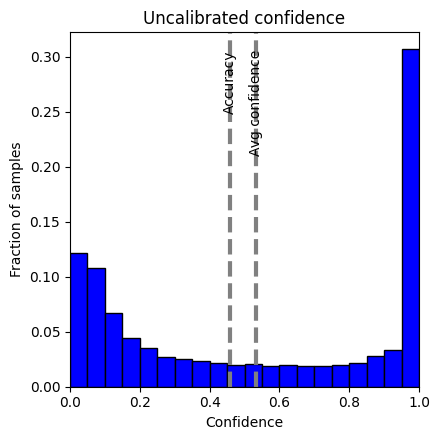

In [8]:
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

Path('plots').mkdir(parents=True, exist_ok=True)
conf_tensor, pred = F.softmax(val_logits, dim=1).max(dim=1)
conf = conf_tensor.detach().cpu().numpy()
pred = pred.cpu()
labels = val_labels.cpu()
acc = (pred == labels).float().mean().item()
avg_conf = conf.mean().item()

bins = np.linspace(0.0, 1.0, 21)
weights = np.ones_like(conf) / conf.size

plt.figure(figsize=(4.5, 4.5))
plt.hist(conf, bins=bins, weights=weights, color='blue', edgecolor='black')
plt.axvline(avg_conf, color='gray', linestyle='--', linewidth=3)
plt.axvline(acc, color='gray', linestyle='--', linewidth=3)
plt.text(avg_conf, 0.95 * plt.gca().get_ylim()[1], 'Avg confidence',
         rotation=90, va='top', ha='center')
plt.text(acc, 0.95 * plt.gca().get_ylim()[1], 'Accuracy',
         rotation=90, va='top', ha='center')
plt.xlabel('Confidence')
plt.ylabel('Fraction of samples')
plt.xlim(0, 1)
plt.title('Uncalibrated confidence')
plt.tight_layout()
plt.savefig('plots/tiny_imagenet_confidence_hist.png', dpi=600)

plt.show()


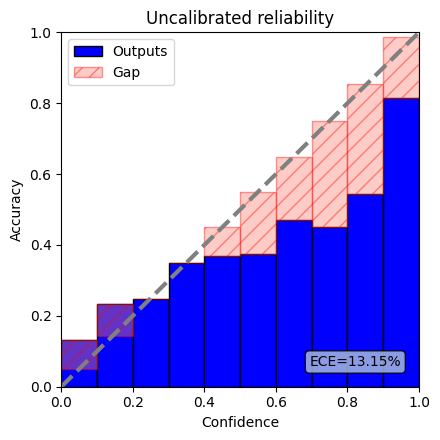

In [9]:
import numpy as np
import matplotlib.pyplot as plt

conf_tensor, pred_tensor = F.softmax(val_logits, dim=1).max(dim=1)
conf = conf_tensor.detach().cpu().numpy()
pred = pred_tensor.detach().cpu().numpy()
labels = val_labels.cpu().numpy()
correct = (pred == labels).astype(np.float32)

n_bins = 10
bins = np.linspace(0.0, 1.0, n_bins + 1)
bin_ids = np.digitize(conf, bins[1:-1], right=True)

bin_acc = np.zeros(n_bins, dtype=np.float32)
bin_conf = np.zeros(n_bins, dtype=np.float32)
bin_frac = np.zeros(n_bins, dtype=np.float32)

for b in range(n_bins):
    mask = bin_ids == b
    if mask.any():
        bin_acc[b] = correct[mask].mean()
        bin_conf[b] = conf[mask].mean()
        bin_frac[b] = mask.mean()

ece = np.sum(np.abs(bin_acc - bin_conf) * bin_frac)

bin_centers = (bins[:-1] + bins[1:]) / 2
bin_width = bins[1] - bins[0]

plt.figure(figsize=(4.5, 4.5))
plt.plot([0, 1], [0, 1], '--', color='gray', linewidth=3)
plt.bar(bin_centers, bin_acc, width=bin_width, color='blue', edgecolor='black', label='Outputs')
gap = bin_conf - bin_acc
plt.bar(bin_centers, gap, bottom=bin_acc, width=bin_width, color='salmon', edgecolor='red',
        alpha=0.4, hatch='//', label='Gap')
plt.xlabel('Confidence')
plt.ylabel('Accuracy')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend(loc='upper left')
plt.text(0.95, 0.05, f'ECE={ece*100:.2f}%', ha='right', va='bottom',
         bbox=dict(boxstyle='round', facecolor='lightsteelblue', alpha=0.8))
plt.title('Uncalibrated reliability')
plt.tight_layout()
plt.savefig('plots/tiny_imagenet_reliability_diagram.png', dpi=600)

plt.show()


### Calibrated confidence and reliability

Run these cells after fitting the temperature and collecting validation logits.
The plots use the same bin counts as the uncalibrated plots above for comparison.


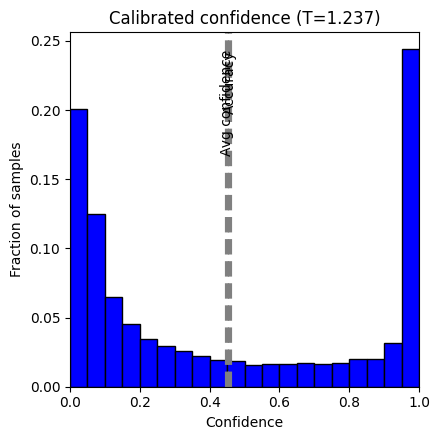

In [10]:
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Reuse validation scores collected after training; apply the fitted temperature.
calibrated_probs = F.softmax(val_logits / temperature, dim=1)
calibrated_conf, calibrated_pred = calibrated_probs.max(dim=1)
conf = calibrated_conf.detach().cpu().numpy()
pred = calibrated_pred.detach().cpu().numpy()
labels = val_labels.detach().cpu().numpy()
Path('plots').mkdir(parents=True, exist_ok=True)

acc = (pred == labels).mean()
avg_conf = conf.mean().item()

bins = np.linspace(0.0, 1.0, 21)
weights = np.ones_like(conf) / conf.size

plt.figure(figsize=(4.5, 4.5))
plt.hist(conf, bins=bins, weights=weights, color='blue', edgecolor='black')
plt.axvline(avg_conf, color='gray', linestyle='--', linewidth=3)
plt.axvline(acc, color='gray', linestyle='--', linewidth=3)
plt.text(avg_conf, 0.95 * plt.gca().get_ylim()[1], 'Avg confidence',
         rotation=90, va='top', ha='center')
plt.text(acc, 0.95 * plt.gca().get_ylim()[1], 'Accuracy',
         rotation=90, va='top', ha='center')
plt.xlabel('Confidence')
plt.ylabel('Fraction of samples')
plt.xlim(0, 1)
plt.title(f'Calibrated confidence (T={temperature:.3f})')
plt.tight_layout()
plt.savefig('plots/tiny_imagenet_calibrated_confidence_hist.png', dpi=600)
plt.show()


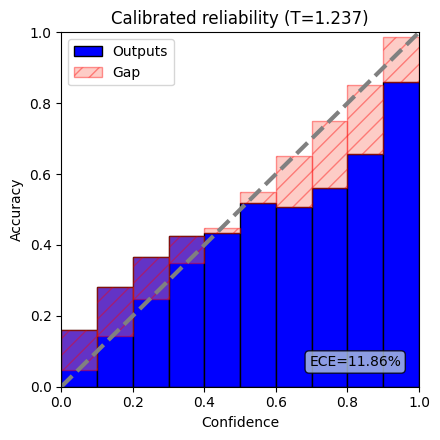

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Use the same calibrated validation predictions as the histogram above.
conf = calibrated_conf.detach().cpu().numpy()
pred = calibrated_pred.detach().cpu().numpy()
labels = val_labels.detach().cpu().numpy()
correct = (pred == labels).astype(np.float32)

n_bins = 10
bins = np.linspace(0.0, 1.0, n_bins + 1)
bin_ids = np.digitize(conf, bins[1:-1], right=True)

bin_acc = np.zeros(n_bins, dtype=np.float32)
bin_conf = np.zeros(n_bins, dtype=np.float32)
bin_frac = np.zeros(n_bins, dtype=np.float32)

for b in range(n_bins):
    mask = bin_ids == b
    if mask.any():
        bin_acc[b] = correct[mask].mean()
        bin_conf[b] = conf[mask].mean()
        bin_frac[b] = mask.mean()

ece = np.sum(np.abs(bin_acc - bin_conf) * bin_frac)

bin_centers = (bins[:-1] + bins[1:]) / 2
bin_width = bins[1] - bins[0]

plt.figure(figsize=(4.5, 4.5))
plt.plot([0, 1], [0, 1], '--', color='gray', linewidth=3)
plt.bar(bin_centers, bin_acc, width=bin_width, color='blue', edgecolor='black', label='Outputs')
gap = bin_conf - bin_acc
plt.bar(bin_centers, gap, bottom=bin_acc, width=bin_width, color='salmon', edgecolor='red',
        alpha=0.4, hatch='//', label='Gap')
plt.xlabel('Confidence')
plt.ylabel('Accuracy')
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.legend(loc='upper left')
plt.text(0.95, 0.05, f'ECE={ece*100:.2f}%', ha='right', va='bottom',
         bbox=dict(boxstyle='round', facecolor='lightsteelblue', alpha=0.8))
plt.title(f'Calibrated reliability (T={temperature:.3f})')
plt.tight_layout()
plt.savefig('plots/tiny_imagenet_calibrated_reliability_diagram.png', dpi=600)

plt.show()
